# LLM from Scratch — Indian Village 2050
### Educational Nano-GPT project | PyTorch | Google Colab | Rural health futures

**Repository:** `llm-from-scratch-indian-village-2050`

This notebook builds a tiny decoder-only Transformer language model from scratch and trains it on a **small, synthetic fictional corpus** about how rural services might work in India in 2050, with a focus on healthcare access, diagnostic workflows, telemedicine, public health, climate resilience, and village infrastructure.

> **Important safety boundary:** This is a machine-learning education demo, not a medical device. The generated text is fictional and can be wrong. It must not diagnose people, recommend treatments, interpret real test results, or replace qualified clinicians. In a real care pathway, trained health professionals select and interpret tests, confirm findings, explain uncertainty, and decide treatment. Emergency symptoms require immediate local emergency care.

## Learning objectives

By the end, you will have practiced:

1. Building a small text corpus and character-level tokenizer.
2. Creating train/validation sequences for next-token prediction.
3. Implementing causal self-attention, a Transformer block, and a GPT-style language model.
4. Training with cross-entropy loss and AdamW.
5. Generating sample text and evaluating validation loss.
6. Saving a model checkpoint and exporting a reusable corpus.

### Hypothetical 2050 care journey (conceptual, not a clinical protocol)

A village resident could access a community health worker, a local clinic, or a telehealth hub. Depending on the complaint and clinical judgement, the clinician might request a test such as a blood count, glucose measurement, urine test, imaging, or a confirmatory laboratory test. Results would be quality-checked and interpreted alongside history and examination; urgent or complex cases would be referred to an appropriate facility. AI could assist with translation, scheduling, summarization, and decision support—but not autonomously decide a diagnosis or treatment.

## 1. Environment setup

This notebook runs on CPU, but a GPU can speed up training. In Colab, select **Runtime → Change runtime type → T4 GPU** if available.

In [2]:
import math
import os
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 2050
random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cpu
Device: cpu


## 2. Create a small synthetic futuristic corpus

The corpus is deliberately compact so the model can train quickly in Colab. It is authored for this notebook, not collected from patient records. The model learns text patterns; it does **not** learn verified medical knowledge.

In [3]:
documents = [
    "In 2050, a village health hub connects residents with a trained community health worker and a licensed clinician.",
    "A resident describes symptoms in their preferred language. The health hub provides translation so the clinician can understand the history accurately.",
    "The clinician reviews symptoms, medical history, examination findings, and risk factors before deciding whether any test is appropriate.",
    "A point-of-care glucose measurement may be considered when clinically appropriate, and the result must be interpreted by a qualified health professional.",
    "A blood count, urine analysis, imaging study, or laboratory test may be requested depending on the clinical question and local guidelines.",
    "A test result is checked for identity, sample quality, units, reference ranges, and possible measurement error before it is used in care.",
    "One test rarely answers every question. Clinicians may repeat a test, request a confirmatory test, or refer a resident to a higher-level facility.",
    "The village clinic uses secure consent-based records. Only authorized care-team members can access a resident's identifiable health information.",
    "An AI assistant can summarize a visit, translate health education, explain how to prepare for an appointment, and help schedule follow-up.",
    "The AI assistant must communicate uncertainty, avoid inventing results, and direct clinical decisions to qualified health professionals.",
    "When warning signs suggest an emergency, the care team arranges urgent assessment and transport rather than relying on a chatbot.",
    "A telemedicine room supports a video consultation when travel is difficult, while a local health worker can help collect measurements when trained to do so.",
    "Solar microgrids power refrigeration for temperature-sensitive supplies and keep essential clinic devices running during outages.",
    "Connected devices may send measurements to a care team, but sensor readings require calibration, context, and human review.",
    "Public-health teams monitor anonymized trends to plan vaccination outreach, clean-water projects, and seasonal disease prevention.",
    "Data used for community planning is minimized and protected. Individual patient data is not exposed in public dashboards.",
    "A resident receives an explanation of the care plan, warning signs, follow-up date, and where to seek help if symptoms worsen.",
    "Local-language learning hubs provide health literacy lessons and help residents ask informed questions during consultations.",
    "Climate alerts help clinics prepare for heat waves, flooding, and disruptions to roads or medicine deliveries.",
    "The village health network combines local knowledge, reliable diagnostics, secure digital infrastructure, and accountable clinical care.",
    "A laboratory report is not a treatment plan by itself. The clinician considers the full situation and discusses next steps with the resident.",
    "If a sample is contaminated or the result conflicts with the clinical picture, the clinician may request a new sample or another method.",
    "The system records when a result was produced, which instrument was used, and whether quality-control checks passed.",
    "Health workers receive continuing training in privacy, consent, infection prevention, device use, and respectful communication.",
    "An AI system must not claim certainty when evidence is missing. It should say what it does not know and recommend human review.",
    "In 2050, technology supports access and coordination, while clinical responsibility remains with qualified professionals and health services."
]

corpus = "\n\n".join(documents)
print("Documents:", len(documents))
print("Corpus characters:", len(corpus))
print(corpus[:500])

Documents: 26
Corpus characters: 3513
In 2050, a village health hub connects residents with a trained community health worker and a licensed clinician.

A resident describes symptoms in their preferred language. The health hub provides translation so the clinician can understand the history accurately.

The clinician reviews symptoms, medical history, examination findings, and risk factors before deciding whether any test is appropriate.

A point-of-care glucose measurement may be considered when clinically appropriate, and the resu


## 3. Character-level tokenizer

A character tokenizer is easy to understand and useful for a from-scratch demonstration. It is not the usual choice for a modern production LLM, which typically uses a subword tokenizer.

In [4]:
chars = sorted(set(corpus))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(text):
    return [stoi[ch] for ch in text if ch in stoi]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(corpus), dtype=torch.long)
split = int(0.9 * len(data))
train_data = data[:split]
val_data = data[split:]

print("Vocabulary size:", vocab_size)
print("All tokens:", len(data))
print("Train tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("Round trip:", decode(encode("village 2050")) if all(c in stoi for c in "village 2050") else "Some characters not in corpus")

Vocabulary size: 46
All tokens: 3513
Train tokens: 3161
Validation tokens: 352
Round trip: village 2050


## 4. Training batches

Each input sequence contains `block_size` characters. The target is the same sequence shifted one character to the right, so the model learns to predict the next character.

In [5]:
batch_size = 16
block_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data
    if len(source) <= block_size + 1:
        raise ValueError("Not enough tokens for block_size. Reduce block_size or expand corpus.")
    ix = torch.randint(len(source) - block_size - 1, (batch_size,))
    x = torch.stack([source[i:i+block_size] for i in ix])
    y = torch.stack([source[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)
print("Example input:", repr(decode(xb[0].tolist())))
print("Example target:", repr(decode(yb[0].tolist())))

Input batch shape: torch.Size([16, 32])
Target batch shape: torch.Size([16, 32])
Example input: 's ask informed questions during '
Example target: ' ask informed questions during c'


## 5. Build a decoder-only Transformer from scratch

The implementation includes token embeddings, positional embeddings, causal self-attention, a feed-forward network, residual connections, layer normalization, and a next-character prediction head.

**Attention scaling note:** the attention scores are divided by `sqrt(head_size)`, the dimension of each query/key head—not the full embedding dimension.

In [11]:
# Slightly larger educational model. Retrain from scratch after changing these.
batch_size = 16
block_size = 128          # wider context than the original 32
max_iters = 5000
eval_interval = 250
learning_rate = 3e-4       # smaller LR for more stable optimization
eval_iters = 30

n_embd = 64
n_head = 4
n_layer = 3
dropout = 0.05

assert n_embd % n_head == 0

In [7]:
class Head(nn.Module):
    """One causal self-attention head."""
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                       # (B, T, head_size)
        q = self.query(x)                     # (B, T, head_size)
        scores = q @ k.transpose(-2, -1)      # (B, T, T)
        scores = scores * (k.shape[-1] ** -0.5)
        scores = scores.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        v = self.value(x)
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        # Pre-layer-normalization + residual connections
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class Village2050GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > block_size:
            raise ValueError(f"Sequence length {T} exceeds block_size {block_size}")
        tok_emb = self.token_embedding_table(idx)
        pos = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding_table(pos)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-4)
            probs = F.softmax(logits, dim=-1)
            next_idx = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_idx), dim=1)
        return idx


model = Village2050GPT().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 29,294


## 6. Evaluate and train

The loss is cross-entropy for next-character prediction. Lower loss means the model is better at predicting held-out character sequences from this tiny corpus; it does **not** mean that its health information is accurate or safe.

In [8]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}
    for split_name in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split_name)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        results[split_name] = losses.mean().item()
    model.train()
    return results


optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
history = []

for step in range(max_iters):
    if step % eval_interval == 0 or step == max_iters - 1:
        losses = estimate_loss()
        history.append({"step": step, **losses})
        print(f"step {step:4d}: train loss {losses['train']:.3f}, val loss {losses['val']:.3f}")

    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

step    0: train loss 4.068, val loss 4.062
step  200: train loss 2.483, val loss 2.728
step  400: train loss 2.315, val loss 2.619
step  600: train loss 2.221, val loss 2.578
step  800: train loss 2.116, val loss 2.526
step 1000: train loss 2.052, val loss 2.495
step 1199: train loss 1.971, val loss 2.463


## 7. Plot the learning curve

A widening gap between training and validation loss can indicate overfitting. With this very small corpus, overfitting is expected and the curve is only a teaching aid.

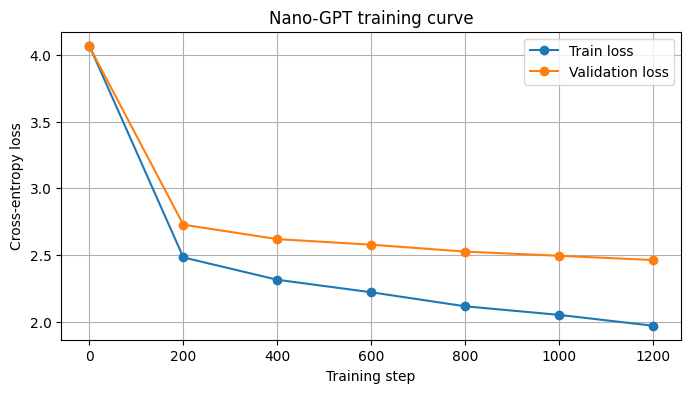

In [9]:
import matplotlib.pyplot as plt

steps = [item["step"] for item in history]
train_losses = [item["train"] for item in history]
val_losses = [item["val"] for item in history]

plt.figure(figsize=(8, 4))
plt.plot(steps, train_losses, marker="o", label="Train loss")
plt.plot(steps, val_losses, marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Nano-GPT training curve")
plt.legend()
plt.grid(True)
plt.show()

## 7A. Why a tiny LLM may not repeat the training text exactly

A next-character model learns probabilities, not a searchable database of exact passages. A low temperature makes token choices less random, but does not guarantee verbatim recall. The original 32-character context also forgets earlier prompt characters quickly.

This project now uses a **hybrid approach**:
- exact source-prefix match → return the stored continuation verbatim;
- no exact match → generate with the Transformer, clearly labeled as generated text.

The retrieval path is what guarantees exact continuation when the prompt matches a source document. The larger context/model configuration may improve local continuation, but it does not guarantee exact memorization. Because the corpus is tiny, the model may overfit; evaluate validation loss and inspect samples.

## 8. Generate a sample

The model is a tiny character-level language model trained on a few dozen short documents. Expect repetition, broken sentences, or incorrect statements. Treat output as a demonstration of generation mechanics only.

In [12]:
# Hybrid answer strategy:
# 1) If a prompt is found inside a source document, return the exact source continuation.
# 2) Otherwise, fall back to the tiny language model.
# Exact retrieval is the correct mechanism for exact-match behavior; temperature is not.

def exact_prefix_completion(prompt, docs=documents):
    prompt_norm = " ".join(prompt.lower().split())
    for doc in docs:
        doc_norm = " ".join(doc.lower().split())
        pos = doc_norm.find(prompt_norm)
        if pos >= 0:
            # Preserve exact original spelling/punctuation in the continuation.
            original_pos = doc.lower().find(prompt.lower())
            if original_pos >= 0:
                return doc[original_pos + len(prompt):], doc
    return None, None

prompt = "In 2050, a village health hub"
continuation, matched_doc = exact_prefix_completion(prompt)

if continuation is not None:
    print("Mode: EXACT CORPUS MATCH")
    print("Prompt:", prompt)
    print("Completion:", prompt + continuation)
    print("Matched source document:", matched_doc)
else:
    print("Mode: MODEL GENERATION (not guaranteed to reproduce training text)")
    unknown = [ch for ch in prompt if ch not in stoi]
    if unknown:
        print("Prompt has characters outside the vocabulary:", unknown)
    else:
        model.eval()
        context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
        generated = model.generate(context, max_new_tokens=180, temperature=0.7)
        print(decode(generated[0].tolist()))

In 2050, the village clicical calin canguan cange cand thesind thes th


## 9. Save model checkpoint and corpus

The checkpoint includes model weights, vocabulary, and configuration. For a real project, also track the code version, dataset version, training configuration, and evaluation results.

In [13]:
project_dir = Path("llm-from-scratch-indian-village-2050")
project_dir.mkdir(exist_ok=True)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "stoi": stoi,
    "itos": itos,
    "config": {
        "vocab_size": vocab_size,
        "block_size": block_size,
        "n_embd": n_embd,
        "n_head": n_head,
        "n_layer": n_layer,
        "dropout": dropout,
        "seed": SEED,
    },
}
torch.save(checkpoint, project_dir / "village2050_gpt.pt")
(project_dir / "synthetic_village2050_corpus.txt").write_text(corpus, encoding="utf-8")

print("Saved:")
for path in sorted(project_dir.iterdir()):
    print("-", path, f"({path.stat().st_size:,} bytes)")

Saved:
- llm-from-scratch-indian-village-2050/synthetic_village2050_corpus.txt (3,513 bytes)
- llm-from-scratch-indian-village-2050/village2050_gpt.pt (172,725 bytes)


## 10. Next steps for a stronger portfolio project

- **Data:** Expand the fictional corpus with reviewed public-health education and rural infrastructure material. Keep licensing and provenance for every source; do not use private patient records.
- **Evaluation:** Track validation loss, repetition rate, prompt coverage, and a human-reviewed set of safe/unsafe generations. A low language-model loss is not a clinical quality metric.
- **Safety:** Add explicit refusal behavior for diagnosis, prescribing, and interpretation of real patient results; direct users to qualified clinicians. Test in Indian languages with qualified reviewers.
- **Retrieval:** For a more reliable educational assistant, retrieve from approved, versioned health-education sources and show citations. Retrieval does not by itself make the system clinically safe.
- **Production:** Add authentication, consent, encryption, audit logs, monitoring, incident response, data minimization, and a clinician-governed approval process.
- **Deployment:** Package a non-clinical demo behind FastAPI; clearly label it as experimental and prevent it from being used for clinical decisions.

### Suggested repository layout

```text
llm-from-scratch-indian-village-2050/
├── llm_from_scratch_indian_village_2050.ipynb
├── README.md
├── synthetic_village2050_corpus.txt
├── requirements.txt
└── .gitignore
```

### Suggested `requirements.txt`

```text
torch
matplotlib
jupyter
```

### Suggested Git commands

```bash
git init
git add llm_from_scratch_indian_village_2050.ipynb README.md synthetic_village2050_corpus.txt requirements.txt
git commit -m "Build Village 2050 nano-GPT from scratch"
git branch -M main
git remote add origin https://github.com/YOUR_USERNAME/llm-from-scratch-indian-village-2050.git
git push -u origin main
```

Replace `YOUR_USERNAME` with your GitHub username. Never commit API keys, credentials, or identifiable health data.